PSET5 (Scroll for PSET 6 ) 

Setting up Grid and initial conditions and defining function for matrix discretized laplacian matrix A applied to vector phi

In [16]:
import numpy as np


N = 128

# grid set up and matriceies for neighbors lookup
phi = np.zeros([N+1,N+1])

xy1 = np.mgrid[0:N+1,0:N+1]
xy = xy1.reshape(2,-1)

xp = np.roll(xy1,-1,axis=1).reshape(2,-1)
xm = np.roll(xy1,1,axis=1).reshape(2,-1)
yp = np.roll(xy1,-1,axis=2).reshape(2,-1)
ym = np.roll(xy1,1,axis=2).reshape(2,-1)


# defining discretized laplacian matrix A applied to vector phi
def A(phi):
  val = phi[xy[0],xy[1]]
  right = phi[xp[0],xp[1]]
  left = phi[xm[0],xm[1]]
  up  = phi[yp[0],yp[1]]
  down = phi[ym[0],ym[1]]

  lap = (-4.0 * val + right + left + up + down).reshape(N+1, N+1)
  Aphi = -lap

  

  return Aphi
  
# Initial conditions/Boundary conditions
rho = np.zeros((N+1, N+1))
def cord_to_grid(x,y,N):
  i = int(round(x*N))
  j = int(round(y*N))
  return (i,j)

# point charges
i1, j1 = cord_to_grid(0.25,0.125,N)
rho[j1,i1] =20.0
i2, j2 = cord_to_grid(0.75,0.125,N)
rho[j2,i2] =20.0
# i1, j1 = cord_to_grid(0.5,0.5,N)
# rho[j1,i1] =20.0
# i2, j2 = cord_to_grid(0.5,0.5,N)
# rho[j2,i2] =20.0


# sqare for phi and zeros on boundaries
l = 0.25
x_c, y_c = 0.625, 0.75

x_min, x_max = x_c - l/2, x_c + l/2
y_min, y_max = y_c - l/2, y_c + l/2

ix_min, jy_min = cord_to_grid(x_min, y_min, N)
ix_max, jy_max = cord_to_grid(x_max, y_max, N)

phi[jy_min:jy_max+1, ix_min:ix_max+1] = 5.0
phi[0,:] = 0.0
phi[-1,:] = 0.0
phi[:,0]  = 0.0
phi[:,-1] = 0.0
# phi[0,:] = 0.0
# phi[-1,:] = 0.0
# phi[:,0]  = 0.0
# phi[:,-1] = 0.0



CG implementation for solving Poisson's euqation

In [17]:

maxiter = 1000
tol = 1e-8
iter = 0
x0 = phi
# defining dotproduct helper
def dot(a,b):
  return np.sum(a*b)

# np arrays for storing CG iterations
x = np.zeros((maxiter + 1, N+1, N+1))
r = np.zeros((maxiter + 1, N+1, N+1))
p = np.zeros((maxiter + 1, N+1, N+1))
rr = np.zeros(maxiter + 1)
b = rho.copy() 
# setting initial conditions/B.C.s

x0 = phi
x[0] = x0

r[0] = b - A(x[0])


r[0,0,:]  = 0.0
r[0,-1,:] = 0.0
r[0,:,0]  = 0.0
r[0,:,-1] = 0.0
r[0,jy_min:jy_max+1,ix_min:ix_max+1] = 0.0


p[0] = r[0].copy()
rr[0] = (dot(r[0],r[0])/dot(b,b))**0.5

for k in range(maxiter):
  Ap = A(p[k])
  #1
  alpha = dot(r[k],r[k])/dot(p[k],Ap)

  #2
  x[k+1] = x[k]+alpha*p[k]
  
  x[k+1,jy_min:jy_max+1, ix_min:ix_max+1] = 5.0
  # resetting B.C.s
  x[k+1,0,:] = 0.0
  x[k+1,-1,:] = 0.0
  x[k+1,:,0]  = 0.0
  x[k+1,:,-1] = 0.0
  #3
  r[k+1] = r[k] - alpha * Ap
  # resetting B.C.s
  r[k+1,jy_min:jy_max+1, ix_min:ix_max+1] = 0.0
  r[k+1,0,:] = 0.0
  r[k+1,-1,:] = 0.0
  r[k+1,:,0]  = 0.0
  r[k+1,:,-1] = 0.0
  #4
  rr[k+1] = (dot(r[k+1],r[k+1])/dot(b,b)) ** 0.5
  print("Residual for iteration ", k, "  is  ", rr[k])
  # convergence check
  if rr[k] < tol:
    iter = k +1
    break
  #5
  beta = dot(r[k+1],r[k+1])/dot(r[k],r[k])
  #6
  p[k+1] = r[k+1] + beta*p[k]






Residual for iteration  0   is   2.2638462845343543
Residual for iteration  1   is   1.413590287176592
Residual for iteration  2   is   1.0557210299546957
Residual for iteration  3   is   0.7981437695010902
Residual for iteration  4   is   0.6778316126950176
Residual for iteration  5   is   0.5658984265705688
Residual for iteration  6   is   0.5049324182365238
Residual for iteration  7   is   0.44284434773755926
Residual for iteration  8   is   0.40589294313659335
Residual for iteration  9   is   0.3665066912878888
Residual for iteration  10   is   0.34166170505814386
Residual for iteration  11   is   0.31446773985959126
Residual for iteration  12   is   0.29658432978691995
Residual for iteration  13   is   0.27667967690840595
Residual for iteration  14   is   0.26316999241177963
Residual for iteration  15   is   0.2479652212052887
Residual for iteration  16   is   0.2373846762893993
Residual for iteration  17   is   0.2253842304046028
Residual for iteration  18   is   0.21683670941484

Plotting resuts 2d then 3d

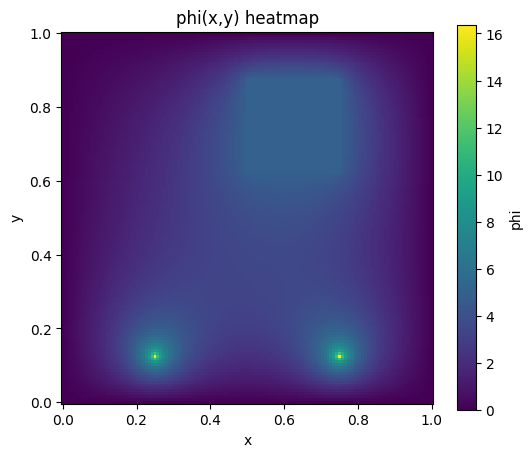

In [18]:
import matplotlib.pyplot as plt

phi_sol = x[iter]   

N = phi_sol.shape[0] - 1
xs = np.linspace(0.0, 1.0, N+1)
ys = np.linspace(0.0, 1.0, N+1)

plt.figure(figsize=(6,5))
plt.pcolormesh(xs, ys, phi_sol, shading='auto', cmap='viridis')
plt.colorbar(label='phi')
plt.xlabel('x')
plt.ylabel('y')
plt.title('phi(x,y) heatmap')
plt.gca().set_aspect('equal')
plt.show()


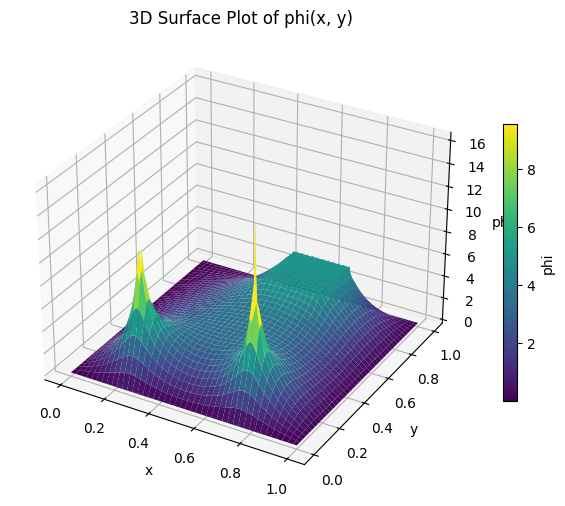

In [19]:
import matplotlib.pyplot as plt
from mpl_toolkits.mplot3d import Axes3D
import numpy as np

phi_sol = x[iter]

N = phi_sol.shape[0] - 1
xs = np.linspace(0.0, 1.0, N+1)
ys = np.linspace(0.0, 1.0, N+1)
X, Y = np.meshgrid(xs, ys)
fig = plt.figure(figsize=(8, 6))
ax = fig.add_subplot(111, projection='3d')

surf = ax.plot_surface(X, Y, phi_sol, cmap='viridis')

ax.set_xlabel("x")
ax.set_ylabel("y")
ax.set_zlabel("phi")
ax.set_title("3D Surface Plot of phi(x, y)")

fig.colorbar(surf, shrink=0.6, label='phi')

plt.show()


PSET 6



In [20]:
q = 0.001 

# helper for resetting BCs for psi
def reset(psi):
  
  # Boundaries
  psi[0, :]  = 0.0
  psi[-1, :] = 0.0
  psi[:, 0]  = 0.0
  psi[:, -1] = 0.0

  # Internal square
  psi[jy_min:jy_max+1, ix_min:ix_max+1] = 0.0
  return psi 
# Discretized application of H to psi, uses A() -> discretized laplacian code from pset 5 
# and adds diagonal term from phi_sol -> solution for phi(x,y) from pset 5
def H(psi):
  psi = reset(psi)
  kin_term = A(psi)
  pot_term = q * phi_sol * psi
  Hpsi = reset(kin_term + pot_term)
  return Hpsi


# helpers for dot product and norm for (N+1 x N+1)-shaped vectors
def dot2d(a, b):
    return np.sum(a * b)

def norm2d(a):
    return np.sqrt(dot2d(a, a))

# Lanczos algorithm that returns T matrix and list of Lanczos vectors given H function, initial vector v0, and num_iters following wikipedia pseudocode
def lanczos(H, v0, num_iters):
  
    v = v0 / norm2d(v0)  # ensure normalized
    V = []          # list to store Lanczos vectors
    alphas = []      
    betas  = [0.0]  # beta_0 = 0

    # initial iterataion step
    V.append(v)
    w = H(v)               
    alpha = dot2d(w, v)      
    alphas.append(alpha)      
    w = w - alpha * v            

    # rest of the recursion
    for j in range(num_iters-1):
        beta = norm2d(w)          
        betas.append(beta)

        v_prev = v
        v = w / beta              
        V.append(v)

        w = H(v) - beta * v_prev  
        alpha = dot2d(w, v)      
        alphas.append(alpha)
        w = w - alpha * v    

    # given lisst of alphas and betas, construct tridiagonal matrix T
    alphas = np.array(alphas, dtype=float)
    betas = np.array(betas, dtype=float) 
    T = np.diag(alphas)
    k = len(alphas)
    off_diagonals = betas[1:k]  
    T += np.diag(off_diagonals, 1) + np.diag(off_diagonals, -1)

    return T, V



Running Lanczos

In [21]:
# inital normalized psi with B.C.s
psi0 = reset(np.random.rand(N+1, N+1))
psi0 /= norm2d(psi0)

# 120 itertions and 5 restarts
num_restarts = 10
num_iters = 120


psi_gs = psi0


for r in range(num_restarts):
    # Lanczos
    T,V = lanczos(H, psi_gs,num_iters)

    # get evals and evecs from T
    evals, evecs = np.linalg.eigh(T)
    idx = np.argmin(evals)
    e0 = evals[idx]
    w = evecs[:, idx]  

    # expanding psi in Lancosz basis
    psi = np.zeros_like(psi_gs)
    for coeff, vj in zip(w, V):
        psi += coeff * vj
    psi = reset(psi)
    psi /= norm2d(psi)
    psi_gs = psi

    # calculating residual 
    res_norm = norm2d(H(psi_gs) - e0 * psi_gs)
    print(f"Restart {r+1}: E0 = {e0:.8f}, Residual ||Hpsi - Espi|| = {res_norm}")

    # checking single precision accuracy

    if res_norm < 1e-8:
        print(f"Needs {r+1} restarts at {num_iters} Lanczos iertions to reach single precision accuracy")
        break
# getting probability diensity |psi_g(x,y)|^2
prob_density = psi_gs**2


# finding P(y<0.5)
j_cut = int(0.5 * N)
P_y_less_half = prob_density[:j_cut, :].sum() / prob_density.sum()
print(f"P(y<0.5) = {P_y_less_half:.6f}")

Restart 1: E0 = 0.00472969, Residual ||Hpsi - Espi|| = 0.0011527957503545125
Restart 2: E0 = 0.00471478, Residual ||Hpsi - Espi|| = 4.8236296156986566e-05
Restart 3: E0 = 0.00471477, Residual ||Hpsi - Espi|| = 8.966779121537535e-07
Restart 4: E0 = 0.00471477, Residual ||Hpsi - Espi|| = 5.969845421677038e-08
Restart 5: E0 = 0.00471477, Residual ||Hpsi - Espi|| = 1.7606830951517808e-09
Needs 5 restarts at 120 Lanczos iertions to reach single precision accuracy
P(y<0.5) = 0.537425


Plotting ground state

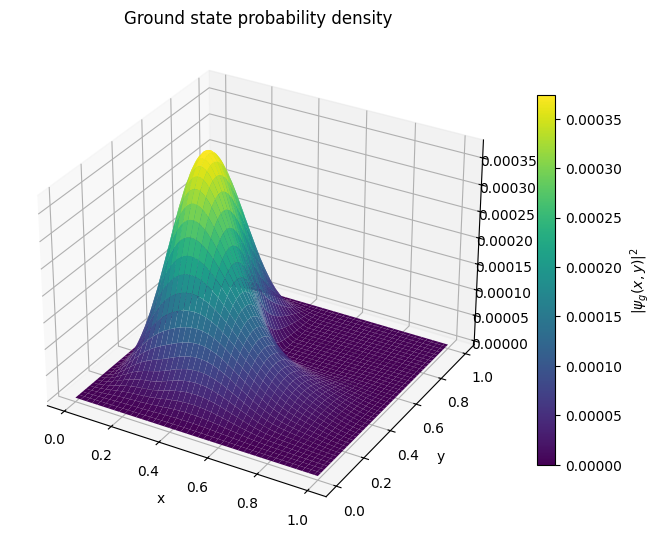

In [22]:

xs = np.linspace(0.0, 1.0, N+1)
ys = np.linspace(0.0, 1.0, N+1)
X, Y = np.meshgrid(xs, ys)
fig = plt.figure(figsize=(8, 8))
ax = fig.add_subplot(111, projection='3d')
surf = ax.plot_surface(X, Y, prob_density, cmap='viridis')

ax.set_xlabel('x')
ax.set_ylabel('y')
ax.set_title('Ground state probability density')
fig.colorbar(surf, shrink=0.6, label=r'$|\psi_g(x,y)|^2$')

plt.show()
